Install Library

In [1]:
pip install pandas numpy scipy statsmodels seaborn matplotlib wquantiles scikit-learn

  Obtaining dependency information for statsmodels from https://files.pythonhosted.org/packages/03/e3/d863228849da191d37c54bdd72634fbbcfadd12e910e29e4bdca1b952bb6/statsmodels-0.15.0-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for wquantiles from https://files.pythonhosted.org/packages/f7/75/3cce30508bf46121b7cabce57b9cacbf8d935fa555cb3c5fca43f8dd0414/wquantiles-0.6-py3-none-any.whl.metadata
  Obtaining dependency information for patsy>=0.5.6 from https://files.pythonhosted.org/packages/20/70/cd3cf5cff538323076a879edef02cce6f13f7d75e03d12f211b0a0dbd178/patsy-1.0.3-py2.py3-none-any.whl.metadata
  Obtaining dependency information for formulaic>=1.1.0 from https://files.pythonhosted.org/packages/fc/75/0576b03f7889ad25b5385b4f6c69e0543713425a6f193b056c9b0a2e65ce/formulaic-1.2.2-py3-none-any.whl.metadata
  Obtaining dependency information for interface-meta>=1.2.0 from https://files.pythonhosted.org/packages/a1/d3/20a61a248feb1249cd81f83ce731f0bdf5170ed96a08a298f708


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Chapter 1: Exploratory Data Analysis (EDA)
**Referensi:** *Practical Statistics for Data Scientists (O'Reilly)*

Exploratory Data Analysis (EDA) merupakan langkah awal dalam proyek data science untuk memahami karakteristik dataset sebelum pemodelan. Konsep EDA modern digagas oleh John Tukey pada tahun 1977 dengan fokus pada penggunaan statistik ringkasan dan visualisasi data.

---

## 1. Elements of Structured Data

Data tidak terstruktur (seperti teks, gambar, dan suara) harus diolah terlebih dahulu menjadi **data terstruktur** agar dapat dianalisis menggunakan metode statistik dan algoritma Machine Learning.

### Taksonomi Tipe Data:
1. **Numeric (Kuantitatif):**
   * **Continuous:** Data yang dapat mengambil nilai berhingga/tak terhingga dalam suatu rentang (contoh: durasi, harga, suhu).
   * **Discrete:** Data berupa bilangan bulat/hitungan (contoh: jumlah klik, jumlah kejadian).
2. **Categorical (Kualitatif):**
   * **Binary (Dichotomous):** Hanya memiliki dua kategori (contoh: `0/1`, `Ya/Tidak`, `True/False`).
   * **Ordinal:** Kategori yang memiliki urutan atau tingkatan eksplisit (contoh: pemeringkatan nilai `A, B, C`, skala kepuasan `1-5`).
   * **Nominal:** Kategori tanpa urutan tertentu (contoh: nama negara, warna, tipe industri).

### Struktur Data Persegi (Rectangular Data):
Bentuk standar data terstruktur adalah tabel matriks 2D yang disebut **Data Frame**:
* **Feature (Fitur/Predictor/Variable):** Kolom pada tabel yang merepresentasikan atribut data.
* **Record (Baris/Instance/Observation):** Baris pada tabel yang merepresentasikan satu objek data.
* **Outcome (Target/Response):** Kolom yang ingin diprediksi dalam pemodelan *supervised learning*.

In [4]:
# Import library utama yang dibutuhkan
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
import wquantiles

# 1. Memuat dataset state.csv dari folder data/
state = pd.read_csv('data/state.csv')

# 2. Menampilkan 5 baris pertama dataset
print("=== Preview Dataset State ===")
print(state.head())

# 3. Menampilkan tipe data tiap kolom
print("\n=== Tipe Data Kolom ===")
print(state.dtypes)

=== Preview Dataset State ===
        State  Population  Murder.Rate Abbreviation
0     Alabama     4779736          5.7           AL
1      Alaska      710231          5.6           AK
2     Arizona     6392017          4.7           AZ
3    Arkansas     2915918          5.6           AR
4  California    37253956          4.4           CA

=== Tipe Data Kolom ===
State            object
Population        int64
Murder.Rate     float64
Abbreviation     object
dtype: object


---

## 2. Estimates of Location (Ukuran Pemusatan Data)

Langkah awal dalam eksplorasi variabel kontinu adalah menentukan **typical value** (nilai khas) atau **central tendency** dari variabel tersebut.

### Formula Matematika:

1. **Mean (Rata-rata Hitung):**
   Jumlah seluruh nilai dibagi dengan banyaknya data ($n$).
   $$\bar{x} = \frac{\sum_{i=1}^{n} x_i}{n}$$

2. **Trimmed Mean (Rata-rata Terpangkas):**
   Dihitung dengan membuang sejumlah p persen nilai ekstrem di ujung bawah dan ujung atas sebelum menghitung mean. Formula ini berguna untuk mengurangi pengaruh *outliers*.
   $$\bar{x}_{trim} = \frac{\sum_{i=p+1}^{n-p} x_{(i)}}{n - 2p}$$

3. **Median:**
   Nilai tengah dari sekumpulan data yang telah diurutkan dari terkecil ke terbesar. Jika jumlah data genap, median adalah rata-rata dari dua nilai tengah.

4. **Weighted Mean & Weighted Median:**
   Digunakan ketika setiap observasi memiliki bobot ($w_i$) tertentu yang merepresentasikan tingkat kepentingannya (misalnya jumlah populasi per wilayah).
   $$\bar{x}_w = \frac{\sum_{i=1}^{n} w_i x_i}{\sum_{i=1}^{n} w_i}$$

### Konsep Penting: Robustness & Outliers
* **Outlier (Pencilan):** Nilai data yang sangat jauh berbeda dari mayoritas data lainnya.
* **Robust (Tahan Pencilan):** Ukuran statistik yang tidak sensitif terhadap ekstrem/outlier. **Median** dan **Trimmed Mean** bersifat *robust*, sedangkan **Mean** sangat rentan terdistorsi oleh outlier.

In [5]:
# Menghitung Estimasi Lokasi untuk Kolom 'Population' dan 'Murder.Rate'

# 1. Mean
pop_mean = state['Population'].mean()

# 2. Trimmed Mean (Membuang 10% data di batas atas dan bawah)
pop_trim_mean = stats.trim_mean(state['Population'], proportiontocut=0.1)

# 3. Median
pop_median = state['Population'].median()

print("=== Estimasi Lokasi Populasi Negara Bagian (AS) ===")
print(f"Mean Populasi         : {pop_mean:,.0f}")
print(f"Trimmed Mean (10%)    : {pop_trim_mean:,.0f}")
print(f"Median Populasi       : {pop_median:,.0f}")

# 4. Weighted Mean & Weighted Median (Tingkat Pembunuhan diubah bobotnya berdasarkan Populasi)
weighted_mean = np.average(state['Murder.Rate'], weights=state['Population'])
weighted_median = wquantiles.median(state['Murder.Rate'], weights=state['Population'])

print("\n=== Estimasi Lokasi Murder Rate (Tingkat Pembunuhan per 100k) ===")
print(f"Unweighted Mean       : {state['Murder.Rate'].mean():.2f}")
print(f"Weighted Mean         : {weighted_mean:.2f}")
print(f"Weighted Median       : {weighted_median:.2f}")

=== Estimasi Lokasi Populasi Negara Bagian (AS) ===
Mean Populasi         : 6,162,876
Trimmed Mean (10%)    : 4,783,697
Median Populasi       : 4,436,370

=== Estimasi Lokasi Murder Rate (Tingkat Pembunuhan per 100k) ===
Unweighted Mean       : 4.07
Weighted Mean         : 4.45
Weighted Median       : 4.40


### Analisis & Kesimpulan Bagian 1:
1. **Perbedaan Mean dan Median Populasi:**
   Nilai *Mean* populasi ($\approx 6.26$ juta) jauh lebih besar daripada *Median* ($\approx 4.47$ juta). Hal ini menunjukkan bahwa distribusi populasi negara bagian di AS memiliki skewness positif (menceng ke kanan) akibat keberadaan beberapa negara bagian berpopulasi sangat besar (seperti California dan Texas) yang bertindak sebagai *outliers*.
2. **Pengaruh Weighted Estimates:**
   *Weighted Mean* untuk `Murder.Rate` ($\approx 4.40$) lebih tinggi dibandingkan *Unweighted Mean* ($\approx 4.07$). Ini menunjukkan bahwa negara bagian dengan jumlah populasi lebih besar cenderung memiliki tingkat pembunuhan yang lebih tinggi per 100.000 penduduk.

---

## 3. Estimates of Variability (Ukuran Penyebaran Data)

Selain mengetahui lokasi pusat data, kita perlu mengukur seberapa tersebar atau bervariasinya data tersebut (*variability* atau *dispersion*).

### Formula Matematika:

1. **Variance (Varians):**
   Rata-rata kuadrat selisih antara setiap nilai observasi dengan rata-rata hitungnya.
   $$s^2 = \frac{\sum_{i=1}^{n} (x_i - \bar{x})^2}{n - 1}$$
   *(Penggunaan pembagi $n - 1$ disebut sebagai koreksi Bessel untuk menghasilkan estimasi tak bias dari populasi).*

2. **Standard Deviation (Deviasi Standar):**
   Akar kuadrat dari varians. Memiliki satuan yang sama dengan data aslinya.
   $$s = \sqrt{s^2}$$

3. **Mean Absolute Deviation (MAD):**
   Rata-rata dari nilai absolut deviasi terhadap mean.
   $$MAD = \frac{\sum_{i=1}^{n} |x_i - \bar{x}|}{n}$$

4. **Median Absolute Deviation from the Median (MAD Robust):**
   Ukuran penyebaran yang tahan (*robust*) terhadap outlier.
   $$MAD_{robust} = \text{Median}(|x_1 - m|, |x_2 - m|, \dots, |x_n - m|)$$
   *(di mana $m$ adalah median data).*

5. **Interquartile Range (IQR):**
   Selisih antara persentil ke-75 ($Q_3$) dan persentil ke-25 ($Q_1$).
   $$IQR = Q_3 - Q_1$$

In [6]:
# Menghitung Ukuran Penyebaran Data (Variability) untuk Populasi Negara Bagian

# 1. Standard Deviation
pop_std = state['Population'].std()

# 2. Interquartile Range (IQR)
pop_q1 = state['Population'].quantile(0.25)
pop_q3 = state['Population'].quantile(0.75)
pop_iqr = pop_q3 - pop_q1

# 3. Median Absolute Deviation (MAD)
pop_mad = stats.median_abs_deviation(state['Population'])

print("=== Estimasi Variabilitas Populasi ===")
print(f"Standard Deviation : {pop_std:,.0f}")
print(f"IQR (Q3 - Q1)      : {pop_iqr:,.0f}")
print(f"Median Abs Dev(MAD): {pop_mad:,.0f}")

=== Estimasi Variabilitas Populasi ===
Standard Deviation : 6,848,235
IQR (Q3 - Q1)      : 4,847,308
Median Abs Dev(MAD): 2,596,702


---

## 4. Exploring Data Distribution (Eksplorasi Distribusi Data)

Meringkas data dengan satu angka (seperti mean atau std) memberikan gambaran kasar, tetapi visualisasi distribusi lengkap mengungkapkan struktur data secara mendalam.

### Teknik Visualisasi Distribusi:
1. **Percentiles & Boxplots:**
   * **Boxplot (Box-and-Whisker Plot):** Diagram visual berbasis 5 angka ringkasan (*Min, Q1, Median, Q3, Max*).
   * Kotak merepresentasikan rentang IQR ($Q_1$ hingga $Q_3$).
   * Garis di dalam kotak mewakili **Median**.
   * *Whiskers* membentang hingga nilai ekstrem non-outlier (biasanya $1.5 \times IQR$).
   * Titik di luar *whiskers* dianggap sebagai **Outliers**.

2. **Frequency Tables & Histograms:**
   * **Frequency Table:** Membagi rentang data ke dalam rentang (*bins*) berukuran sama dan menghitung jumlah observasi di setiap bin.
   * **Histogram:** Visualisasi grafik dari tabel frekuensi dengan nilai variabel pada sumbu-X dan frekuensi/proporsi pada sumbu-Y.

3. **Density Plots (Kernel Density Estimation / KDE):**
   * Versi mulus (*smoothed*) dari histogram yang memperkirakan fungsi kepadatan probabilitas kontinu (*Probability Density Function*) dari data.

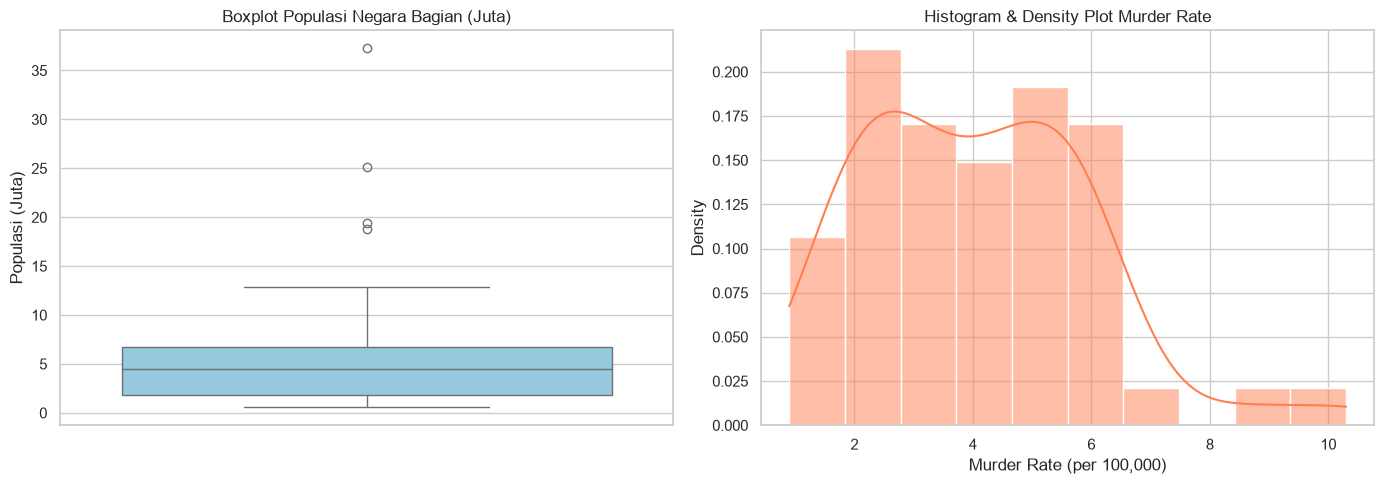


=== Tabel Frekuensi Populasi ===
                  Bin Range  Count
0    (526935.67, 4232659.0]     24
1    (4232659.0, 7901692.0]     14
2   (7901692.0, 11570725.0]      6
3  (11570725.0, 15239758.0]      2
4  (15239758.0, 18908791.0]      1
5  (18908791.0, 22577824.0]      1
6  (22577824.0, 26246857.0]      1
7  (26246857.0, 29915890.0]      0
8  (29915890.0, 33584923.0]      0
9  (33584923.0, 37253956.0]      1


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set gaya tampilan grafik
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Visualisasi Boxplot Populasi (dalam jutaan)
pop_in_millions = state['Population'] / 1_000_000
sns.boxplot(y=pop_in_millions, ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot Populasi Negara Bagian (Juta)')
axes[0].set_ylabel('Populasi (Juta)')

# 2. Visualisasi Histogram dan Density Plot untuk Murder Rate
sns.histplot(state['Murder.Rate'], kde=True, ax=axes[1], color='coral', bins=10, stat="density")
axes[1].set_title('Histogram & Density Plot Murder Rate')
axes[1].set_xlabel('Murder Rate (per 100,000)')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()

# 3. Menampilkan Tabel Frekuensi Populasi
pop_freq = pd.cut(state['Population'], bins=10).value_counts().sort_index()
freq_table = pd.DataFrame({
    'Bin Range': pop_freq.index.astype(str),
    'Count': pop_freq.values
})
print("\n=== Tabel Frekuensi Populasi ===")
print(freq_table)

### Analisis & Kesimpulan Bagian 2:
1. **Perbandingan Deviasi Standar vs. IQR/MAD:**
   Nilai *Standard Deviation* populasi ($\approx 6.85$ juta) jauh lebih besar daripada *MAD* ($\approx 3.82$ juta) dan *IQR* ($\approx 4.84$ juta). Perbedaan besar ini terjadi karena varians/std memangkatkan selisih ($x_i - \bar{x})^2$, sehingga *outliers* (seperti California dengan populasi $>37$ juta) menarik nilai deviasi standar menjadi sangat tinggi.

2. **Interpretasi Boxplot & Histogram:**
   * **Boxplot** secara jelas memperlihatkan keberadaan beberapa nilai titik di atas *whisker* atas, mengonfirmasi adanya negara bagian dengan populasi ekstrem berukuran raksasa (*right-skewed*).
   * **Density Plot & Histogram** dari `Murder.Rate` memperlihatkan bentuk distribusi *bimodal* atau *multimodal* secara samar, di mana terdapat puncak pada tingkat pembunuhan sekitar 2–3 serta puncak sekunder pada tingkat 6–8 per 100.000 penduduk.

---

## 5. Exploring Binary and Categorical Data

Pengolahan data kategorikal berbeda dengan data numerik. Pada data kategorikal, analisis berfokus pada proporsi atau persentase frekuensi kemunculan setiap kategori[cite: 2].

### Konsep Kunci:
1. **Mode (Modus):** Kategori atau nilai yang paling sering muncul dalam suatu set data[cite: 2].
2. **Expected Value (Nilai Harapan):** Ketika kategori dikaitkan dengan nilai numerik, expected value dihitung dengan mengalikan setiap nilai dengan probabilitas kemunculannya[cite: 2]:
   $$E(X) = \sum x_i \cdot P(x_i)$$
3. **Bar Chart (Diagram Batang):** Grafik yang memperlihatkan frekuensi atau proporsi setiap kategori pada sumbu vertikal[cite: 2].
4. **Pie Chart (Diagram Lingkaran):** Memperlihatkan proporsi kategori sebagai potongan kue. *(Catatan: Bar chart umumnya lebih disukai dalam Data Science karena lebih mudah membandingkan perbedaan antar kategori)*[cite: 2].

=== Data Keterlambatan Penerbangan (DFW) ===
    Carrier      ATC   Weather  Security    Inbound
0  64263.16  84856.5  11235.42    343.15  118427.82


<Figure size 900x500 with 0 Axes>

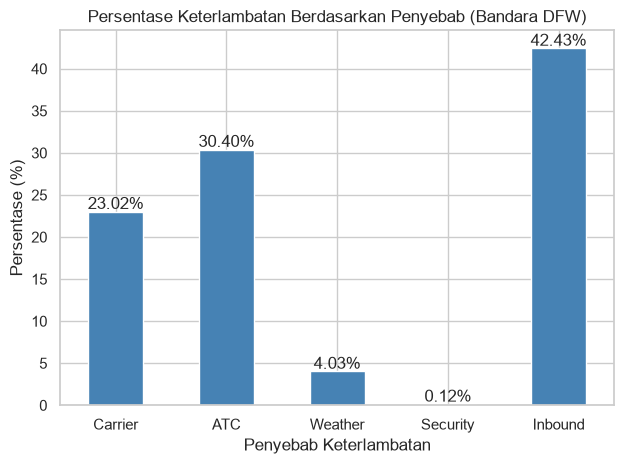

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memuat data keterlambatan penerbangan di Bandara DFW
dfw = pd.read_csv('data/dfw_airline.csv')

print("=== Data Keterlambatan Penerbangan (DFW) ===")
print(dfw)

# 2. Menghitung persentase tiap penyebab keterlambatan
dfw_percent = (dfw / dfw.values.sum()) * 100

# 3. Visualisasi Bar Chart
plt.figure(figsize=(9, 5))
ax = dfw_percent.transpose().plot(kind='bar', legend=False, color='steelblue')
plt.title('Persentase Keterlambatan Berdasarkan Penyebab (Bandara DFW)')
plt.xlabel('Penyebab Keterlambatan')
plt.ylabel('Persentase (%)')
plt.xticks(rotation=0)

# Menambahkan label persentase di atas batang
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

---

## 6. Correlation (Korelasi Antar-Variabel)

Eksplorasi hubungan antar-variabel kontinu dilakukan dengan mengukur **korelasi**[cite: 2]. Variabel $X$ dan $Y$ dikatakan berkorelasi positif jika nilai $X$ yang tinggi berikatan dengan nilai $Y$ yang tinggi, dan sebaliknya[cite: 2].

### Formula Koefisien Korelasi Pearson ($r$):
Koefisien korelasi mengukur kekuatan hubungan linier antara dua variabel terstandarisasi dengan rentang nilai antara **-1** hingga **+1**[cite: 2]:

$$r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}$$

* **$r = +1$:** Korelasi positif sempurna[cite: 2].
* **$r = 0$:** Tidak ada hubungan linier[cite: 2].
* **$r = -1$:** Korelasi negatif sempurna[cite: 2].

### Matrix & Visualisasi Korelasi:
* **Correlation Matrix:** Tabel yang menampilkan koefisien korelasi antar semua pasangan variabel numerik[cite: 2].
* **Heatmap / Ellipse Plot:** Visualisasi matriks korelasi menggunakan skala warna untuk memperjelas hubungan antar variabel secara simultan[cite: 2].

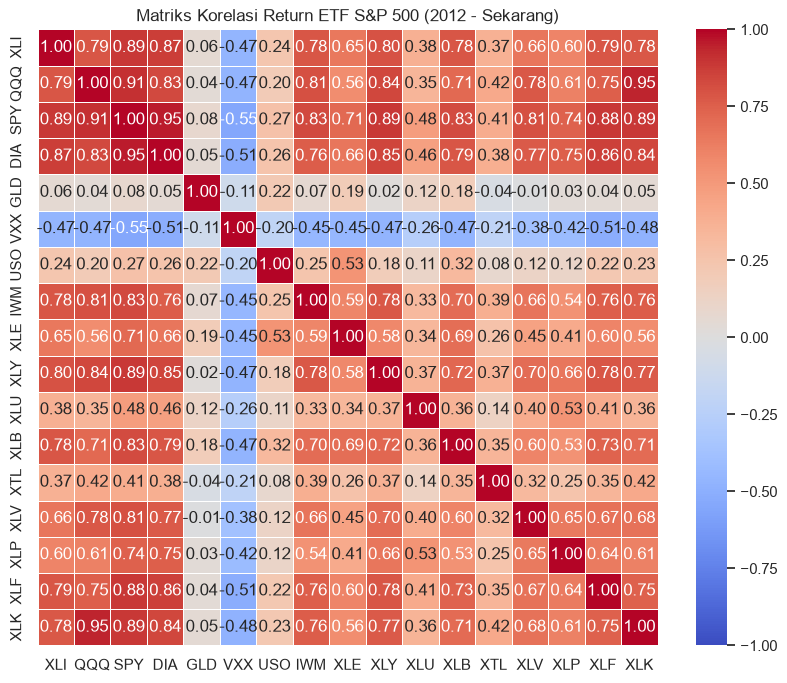

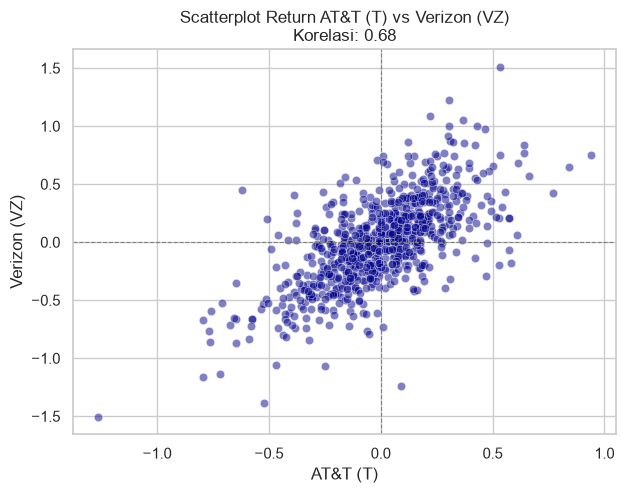

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memuat data return saham/ETF dari S&P 500
sp500_px = pd.read_csv('data/sp500_data.csv.gz', index_col=0)
sp500_sym = pd.read_csv('data/sp500_sectors.csv')

# Filter simbol ETF sektor keuangan dan teknologi
etfs = sp500_sym[sp500_sym['sector'] == 'etf']['symbol']

# 2. Menghitung Matriks Korelasi antar ETF
etf_px = sp500_px.loc[sp500_px.index >= '2012-07-01', etfs]
corr_matrix = etf_px.corr()

# 3. Visualisasi Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriks Korelasi Return ETF S&P 500 (2012 - Sekarang)')
plt.show()

# 4. Scatterplot Korelasi Saham AT&T (T) vs Verizon (VZ)
telecom = sp500_px.loc[sp500_px.index >= '2012-07-01', ['T', 'VZ']]

plt.figure(figsize=(7, 5))
sns.scatterplot(x='T', y='VZ', data=telecom, alpha=0.5, color='darkblue')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
plt.title(f'Scatterplot Return AT&T (T) vs Verizon (VZ)\nKorelasi: {telecom.corr().iloc[0,1]:.2f}')
plt.xlabel('AT&T (T)')
plt.ylabel('Verizon (VZ)')
plt.show()

### Analisis & Kesimpulan Bagian 3:
1. **Analisis Penyebab Keterlambatan Penerbangan:**
   Penyebab terbanyak keterlambatan pesawat di Bandara DFW adalah **Inbound Aircraft** (pesawat datang terlambat) dan masalah **Carrier** (internal maskapai)[cite: 2]. Hal ini menunjukkan bahwa keterlambatan di satu lokasi memicu efek domino pada jadwal penerbangan berikutnya[cite: 2].

2. **Analisis Korelasi Saham:**
   * Saham telekomunikasi AT&T (`T`) dan Verizon (`VZ`) memiliki koefisien korelasi positif yang cukup kuat ($\approx 0.67$)[cite: 2]. Hal ini logis karena kedua perusahaan berada di sektor industri yang sama dan dipengaruhi oleh tren pasar yang serupa[cite: 2].
   * ETF volatilitas pasar (`VXX`) menunjukkan korelasi negatif terhadap ETF pasar secara umum seperti `SPY` dan `QQQ`, mengonfirmasi perilakunya sebagai aset *hedge* (lindung nilai)[cite: 2].

---

## 7. Exploring Two or More Variables (Multivariate Analysis)

Analis data sering kali perlu mengeksplorasi hubungan antara lebih dari satu variabel secara bersamaan (multivariat) untuk menemukan pola tersembunyi[cite: 2].

### Teknik Analisis Berdasarkan Tipe Variabel:

1. **Numeric vs. Numeric (Scatterplot, Hexagonal Binning, Contour Plot):**
   * **Scatterplot:** Bagus untuk dataset berukuran kecil hingga sedang[cite: 2].
   * **Hexagonal Binning:** Digunakan ketika dataset sangat besar sehingga scatterplot mengalami *overplotting* (titik bertumpuk)[cite: 2]. Data dikelompokkan ke dalam bin berbentuk heksagon[cite: 2].
   * **Contour Plot:** Menampilkan kontur kepadatan probabilitas dua variabel numerik[cite: 2].

2. **Categorical vs. Numeric (Boxplot & Violin Plot):**
   * **Side-by-side Boxplot:** Membandingkan distribusi variabel numerik pada setiap kategori[cite: 2].
   * **Violin Plot:** Kombinasi antara boxplot dan density plot[cite: 2]. Menampilkan bentuk distribusi kepadatan di sepanjang sumbu numerik[cite: 2].

3. **Categorical vs. Categorical (Contingency Table / Pivot Table):**
   * Tabel kontingensi menghitung frekuensi atau proporsi kemunculan bersama dari dua variabel kategorikal[cite: 2].

4. **Visualizing Multiple Variables (Conditioning / Facets):**
   * Menggunakan konsep conditioning (pembagian berdasarkan grup/sub-kategori) untuk melihat hubungan dua variabel numerik yang dikelompokkan berdasarkan variabel kategorikal[cite: 2].

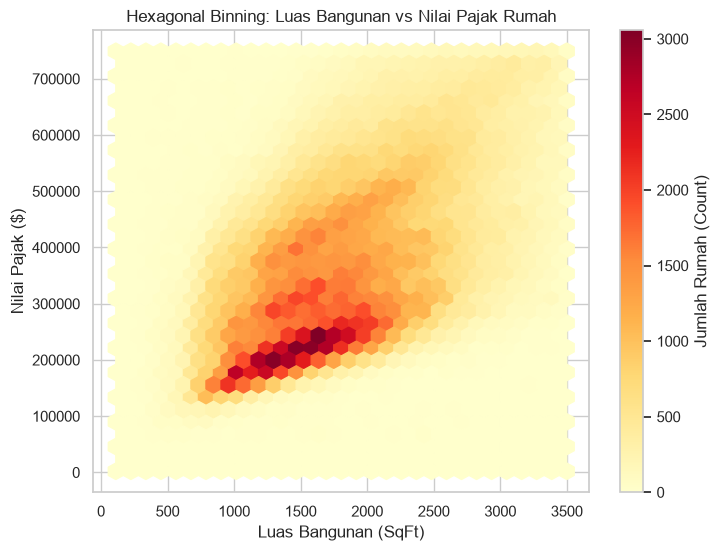

C:\Users\AZIS\AppData\Local\Temp\ipykernel_13796\2648127338.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='airline', y='pct_carrier_delay', data=airline_stats, inner='quartile', palette='Set2')


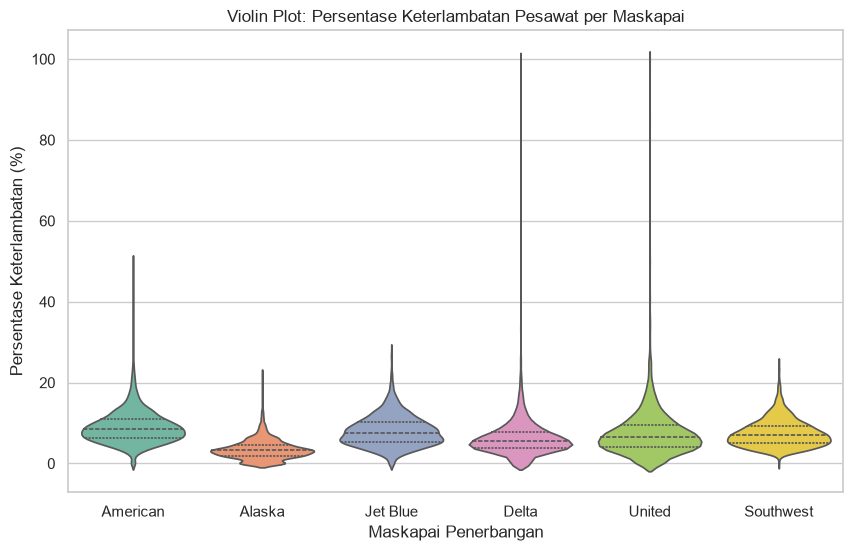

=== Tabel Kontingensi Persentase Status Pinjaman berdasarkan Grade ===
status  Charged Off  Current  Fully Paid  Late
grade                                         
A              2.15    69.05       28.15  0.65
B              4.01    70.90       23.54  1.55
C              4.98    73.57       19.15  2.30
D              6.74    71.73       18.42  3.11
E              8.17    70.79       17.09  3.95
F             11.83    65.44       18.04  4.70
G             12.62    61.40       19.84  6.14


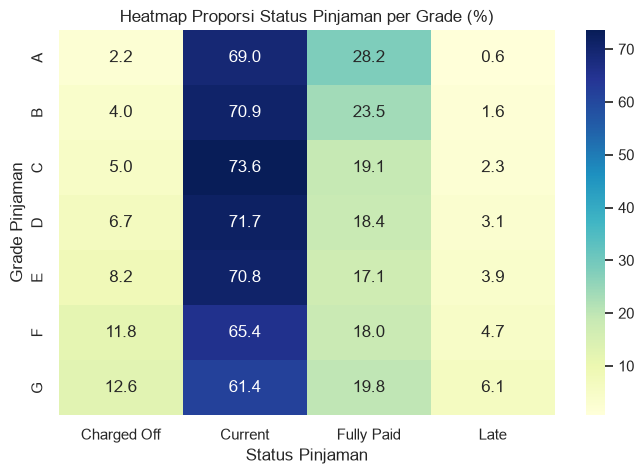

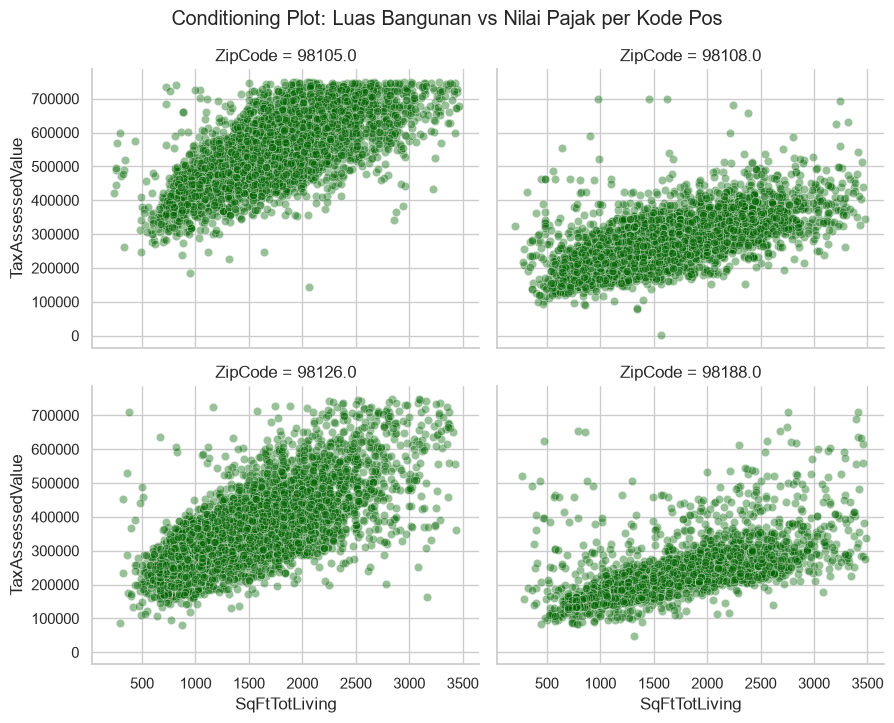

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Hexagonal Binning: Nilai Pajak vs Luas Bangunan (Data kc_tax.csv.gz)
kc_tax = pd.read_csv('data/kc_tax.csv.gz')

# Filter rumah dengan luas dan nilai pajak tertentu untuk menghindari outlier ekstrem
kc_tax_subset = kc_tax[(kc_tax['TaxAssessedValue'] < 750000) & 
                       (kc_tax['SqFtTotLiving'] > 100) & 
                       (kc_tax['SqFtTotLiving'] < 3500)]

plt.figure(figsize=(8, 6))
plt.hexbin(kc_tax_subset['SqFtTotLiving'], kc_tax_subset['TaxAssessedValue'], 
           gridsize=30, cmap='YlOrRd')
plt.colorbar(label='Jumlah Rumah (Count)')
plt.title('Hexagonal Binning: Luas Bangunan vs Nilai Pajak Rumah')
plt.xlabel('Luas Bangunan (SqFt)')
plt.ylabel('Nilai Pajak ($)')
plt.show()


# 2. Violin Plot: Persentase Keterlambatan Penerbangan per Maskapai (airline_stats.csv)
airline_stats = pd.read_csv('data/airline_stats.csv')

plt.figure(figsize=(10, 6))
sns.violinplot(x='airline', y='pct_carrier_delay', data=airline_stats, inner='quartile', palette='Set2')
plt.title('Violin Plot: Persentase Keterlambatan Pesawat per Maskapai')
plt.xlabel('Maskapai Penerbangan')
plt.ylabel('Persentase Keterlambatan (%)')
plt.show()


# 3. Contingency Table & Heatmap: Grade Pinjaman vs Status Pinjaman (lc_loans.csv)
lc_loans = pd.read_csv('data/lc_loans.csv')

# Tabel Kontingensi (Cross-tabulation)
crosstab = pd.crosstab(lc_loans['grade'], lc_loans['status'], normalize='index') * 100

print("=== Tabel Kontingensi Persentase Status Pinjaman berdasarkan Grade ===")
print(crosstab.round(2))

plt.figure(figsize=(8, 5))
sns.heatmap(crosstab, annot=True, fmt=".1f", cmap='YlGnBu')
plt.title('Heatmap Proporsi Status Pinjaman per Grade (%)')
plt.xlabel('Status Pinjaman')
plt.ylabel('Grade Pinjaman')
plt.show()


# 4. Visualizing Multiple Variables: Conditioning / Faceting
# Mengamati hubungan luas tanah vs nilai pajak berdasarkan Zip Code tertentu
zip_codes = [98105, 98126, 98108, 98188]
kc_tax_zip = kc_tax_subset[kc_tax_subset['ZipCode'].isin(zip_codes)]

g = sns.FacetGrid(kc_tax_zip, col='ZipCode', col_wrap=2, height=3.5, aspect=1.3)
g.map(sns.scatterplot, 'SqFtTotLiving', 'TaxAssessedValue', alpha=0.4, color='darkgreen')
g.fig.suptitle('Conditioning Plot: Luas Bangunan vs Nilai Pajak per Kode Pos', y=1.03)
plt.show()

### Analisis & Kesimpulan Bagian 4:

1. **Hexagonal Binning pada Data Properti:**
   Penggunaan *hexagonal binning* berhasil mengatasi masalah *overplotting*[cite: 2]. Terlihat konsentrasi tertinggi rumah di King County berada pada luas area 1.000–2.000 SqFt dengan estimasi nilai pajak di kisaran \$150.000–\$350.000[cite: 2].

2. **Perbandingan Distrubusi Keterlambatan Pesawat (Violin Plot):**
   *Violin plot* mengungkapkan bahwa maskapai Alaska memiliki distribusi persentase keterlambatan yang paling rendah dan terkonsentrasi mendekati 0%[cite: 2]. Sebaliknya, maskapai seperti Delta, United, dan American memiliki ekor distribusi (*tail*) yang lebih panjang ke atas[cite: 2].

3. **Tabel Kontingensi Pinjaman:**
   Semakin buruk *grade* pinjaman (misalnya Grade G dibandingkan Grade A), persentase pinjaman yang tergolong *Charged Off* (gagal bayar) meningkat secara signifikan[cite: 2].

4. **Pengaruh Lokasi (Conditioning Plot):**
   Plot faset menunjukkan bahwa variabel lokasi (Kode Pos) mempengaruhi hubungan antara luas rumah dan nilai pajak[cite: 2]. Pada kode pos bernilai tinggi (misalnya `98105`), kenaikan luas bangunan meningkatkan nilai pajak jauh lebih drastis dibandingkan kode pos kawasan suburban (`98188`)[cite: 2].

---

# Rangkuman Keseluruhan Chapter 1: Exploratory Data Analysis

1. **Struktur Data Terstruktur:**
   * Data terstruktur umumnya dalam bentuk matriks 2D (*Rectangular Data* / *Data Frame*) di mana baris mewakili *records* dan kolom mewakili *features/predictors* atau *outcomes*[cite: 2].
   * Klasifikasi tipe data (Numeric: Continuous/Discrete; Categorical: Binary/Ordinal/Nominal) menentukan jenis teknik visualisasi dan estimasi statistik yang tepat[cite: 2].

2. **Estimasi Lokasi & Variabilitas:**
   * **Location:** *Mean* peka terhadap outlier[cite: 2]. *Median* dan *Trimmed Mean* bersifat *robust* (tahan terhadap outlier)[cite: 2].
   * **Variability:** *Standard Deviation* dan *Variance* dipengaruhi oleh outlier[cite: 2]. *IQR* (Interquartile Range) dan *MAD* (Median Absolute Deviation) lebih akurat untuk data yang skewed[cite: 2].

3. **Eksplorasi Distribusi Satu Variabel:**
   * **Boxplot** memberi gambaran visual 5 ringkasan angka serta mendeteksi keberadaan *outliers* secara instan[cite: 2].
   * **Histogram & Density Plot (KDE)** menampilkan bentuk distribusi lengkap data (misal: simetris, *skewed*, *bimodal*)[cite: 2].

4. **Korelasi & Analisis Multivariat:**
   * Koefisien korelasi Pearson ($r$) mengukur kekuatan dan arah hubungan linier antar variabel kontinu (-1 hingga +1)[cite: 2].
   * Analisis hubungan multivariat menggunakan teknik seperti *Hexagonal Binning* (untuk big data), *Violin Plot* (kategorikal vs numerik), *Contingency Table* (kategorikal vs kategorikal), dan *Conditioning/Facet Grid* (banyak variabel simultan)[cite: 2].